In [1]:
import pandas as pd, numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
import joblib

# load clean data
df = pd.read_csv("../data/processed/clean.csv",
                 parse_dates=["created_at", "actual_delivery_time"])

df["available_dashers"] = df["total_onshift_dashers"] - df["total_busy_dashers"]
df["busy_ratio"] = df["total_busy_dashers"] / (df["total_onshift_dashers"] + 1)
df["orders_per_dasher"] = df["total_outstanding_orders"] / (df["total_onshift_dashers"] + 1)
df["avg_item_price"] = df["subtotal"] / df["total_items"].clip(lower=1)
df["is_weekend"] = (df["weekday"] >= 5).astype(int)

# sort by time, first 80% = train, last 20% = test
df = df.sort_values("created_at", kind="stable").reset_index(drop=True)
split = int(len(df) * 0.8)

X = df.drop(columns=["created_at", "actual_delivery_time", "duration_min", "store_id"])
y = df["duration_min"]
X = pd.get_dummies(X, columns=["market_id", "order_protocol", "store_primary_category"], dtype=int)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]
print(X_train.shape, X_test.shape)

(157826, 108) (39457, 108)


In [2]:
checkpoints = [0, 10, 20, 30, 40]

def make_checkpoint_data(X_part, y_part):
    parts_X, parts_y = [], []
    for t in checkpoints:
        still_running = y_part.values > t          # not delivered yet at minute t
        Xt = X_part[still_running].copy()
        Xt["elapsed_min"] = t                      # minutes since the order
        parts_X.append(Xt)
        parts_y.append(y_part[still_running] - t)  # remaining time
    return pd.concat(parts_X), pd.concat(parts_y)

Xd_train, yd_train = make_checkpoint_data(X_train, y_train)
Xd_test, yd_test = make_checkpoint_data(X_test, y_test)

print(Xd_train.shape, Xd_test.shape)
print("orders still running at each checkpoint (test):")
for t in checkpoints:
    print(t, "min:", (y_test.values > t).sum())

(703243, 109) (178903, 109)
orders still running at each checkpoint (test):
0 min: 39457
10 min: 39456
20 min: 39058
30 min: 35048
40 min: 25884


In [5]:
dyn = lgb.LGBMRegressor(objective="regression_l1", n_estimators=500,
                        learning_rate=0.05, num_leaves=31,
                        random_state=42, verbose=-1)
dyn.fit(Xd_train, yd_train)


,learning_rate,0.05
,n_estimators,500
,objective,'regression_l1'
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,class_weight,None
,min_split_gain,0.0


In [4]:
static = lgb.LGBMRegressor(objective="regression_l1", n_estimators=500,
                           learning_rate=0.05, num_leaves=31,
                           random_state=42, verbose=-1)
static.fit(X_train, y_train)
static_pred = static.predict(X_test)

In [6]:
rows = []
for t in checkpoints:
    still_running = y_test.values > t
    real_remaining = y_test.values[still_running] - t

    # naive: order-time ETA minus elapsed (never below 1 min)
    naive = np.clip(static_pred[still_running] - t, 1, None)

    # dynamic model: knows the order is still running at minute t
    Xt = X_test[still_running].copy()
    Xt["elapsed_min"] = t
    dyn_pred = np.clip(dyn.predict(Xt[Xd_train.columns]), 1, None)

    rows.append([t, still_running.sum(),
                 round(np.abs(real_remaining - naive).mean(), 2),
                 round(np.abs(real_remaining - dyn_pred).mean(), 2)])

mae_table = pd.DataFrame(rows, columns=["minutes_since_order", "orders_left",
                                        "MAE_naive", "MAE_dynamic"])
mae_table

,minutes_since_order,orders_left,MAE_naive,MAE_dynamic
0,0,39457,10.90,10.94
1,10,39456,10.90,10.90
2,20,39058,10.87,10.87
3,30,35048,10.99,10.72
4,40,25884,11.78,10.57


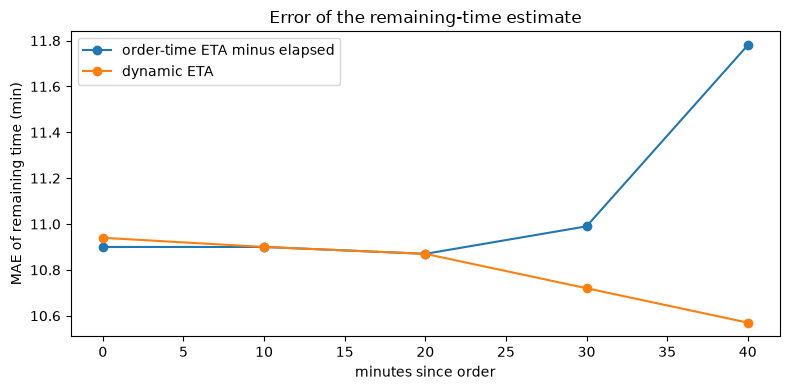

In [7]:
plt.figure(figsize=(8, 4))
plt.plot(mae_table["minutes_since_order"], mae_table["MAE_naive"], marker="o", label="order-time ETA minus elapsed")
plt.plot(mae_table["minutes_since_order"], mae_table["MAE_dynamic"], marker="o", label="dynamic ETA")
plt.xlabel("minutes since order")
plt.ylabel("MAE of remaining time (min)")
plt.title("Error of the remaining-time estimate")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/12_dynamic_eta_mae.png", dpi=150)
plt.show()

In [12]:
# picking a test order that took more than 45 minutes
i = np.where(y_test.values > 45)[0][0]
print("real total time:", round(y_test.values[i], 1), "min")

for t in checkpoints:
    if y_test.values[i] > t:
        row = X_test.iloc[[i]].copy()
        row["elapsed_min"] = t
        left = max(dyn.predict(row[Xd_train.columns])[0], 1)
        print(f"after {t:>2} min: about {left:.0f} min left (total about {t + left:.0f})")

real total time: 45.8 min
after  0 min: about 40 min left (total about 40)
after 10 min: about 29 min left (total about 39)
after 20 min: about 19 min left (total about 39)
after 30 min: about 11 min left (total about 41)
after 40 min: about 6 min left (total about 46)


In [11]:
joblib.dump(dyn, "../models/dynamic_eta.pkl")
joblib.dump(list(Xd_train.columns), "../models/dynamic_columns.pkl")
print("saved")

saved


## Day 4 Findings
1. The dynamic ETA predicts remaining time at 0, 10, 20, 30 and 40 minutes after the order, using only orders still running at that time.
2. Up to 20 minutes, it matches the naive method (order-time ETA minus elapsed time) at about 10.9 min MAE.
3. At 30 minutes the dynamic MAE is 10.72 vs 10.99 naive; at 40 minutes it is 10.57 vs 11.78, an improvement of 1.2 min (10%).
4. The naive method gets worse at late checkpoints because orders still running are the slow ones, which the dynamic model learns.
5. Fewer orders remain at later checkpoints (25,884 of 39,457 at 40 min), and they are a slower group, so MAE across checkpoints is not a trend.
6. The data has no GPS or live progress, so the only new signal is that the order is still running; real live features would improve this much more.